In [26]:
%pip install imbalanced-learn
#import for jupyter
import numpy as np
import pandas as pd
import json
import time
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier 
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict
import matplotlib.pyplot as plt

#opening leonie's data
data = np.load("processed_arrays.npz")
with open("metadata.json") as f:
    meta = json.load(f)

train_raw = pd.read_csv("train_raw.csv")#loading cleaned training data for cross-validation and tuning


In [27]:
#original training data for strat A and B
X_train = data["X_train"]
y_train = data["y_train"]

#SMOTE balanced training data for strat C
X_train_smote = data["X_train_smote"]
y_train_smote = data["y_train_smote"]

#hold-out test data for evaluating ALL three strats
X_test = data["X_test"]
y_test = data["y_test"]


In [28]:
#preparing for cross validation 

X_all = train_raw.drop(columns=["y", "cv_fold"])
y_all = train_raw["y"].values
folds = train_raw["cv_fold"].values

#using leonie's predefined 5 folds 
cv_split = PredefinedSplit(folds) 

#for storing cross validation results and best params
cv_scores = {}
cv_std = {}
best_params = {}

#chose to fine-tune max depth with 13 options to match logistic regression 
param_grid = {"clf__max_depth": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, None]}

#tuning each strat
for strategy in ["A", "B", "C"]:
#creates a preprocessing pipeline dependent on feature type
        preprocessor = ColumnTransformer([("num", StandardScaler(), meta["numeric_cols"]), ("bin", "passthrough", meta["binary_cols"]), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),meta["categorical_cols"])])

        weight = None 

        if strategy == "B": 
            weight = "balanced"

        tree = DecisionTreeClassifier(class_weight=weight, random_state=42)

    
        #creating pipeline for preprocessing and training
        steps = [("prep", preprocessor)]
        #smote for strat C
        if strategy == "C":
            steps.append(("smote", SMOTE(random_state=42)))

        steps.append(("clf", tree))

        pipeline = Pipeline(steps)

        #finding best max depth via cross validation 

        search = GridSearchCV(pipeline, param_grid=param_grid, scoring="average_precision",cv=cv_split,refit=False, return_train_score=True)
        search.fit(X_all, y_all)

        best_params[strategy] = search.best_params_
        cv_scores[strategy] = search.best_score_
        cv_std[strategy] = search.cv_results_["std_test_score"][search.best_index_]
    



In [29]:

#creating final models using best depth from cross validation

tree_A = DecisionTreeClassifier(max_depth=best_params["A"]["clf__max_depth"],random_state=42) #random state 42 from leonie's code
tree_B = DecisionTreeClassifier(max_depth=best_params["B"]["clf__max_depth"],class_weight="balanced",random_state=42) 
tree_C = DecisionTreeClassifier(max_depth=best_params["C"]["clf__max_depth"],random_state=42) 

#train strategy a

start = time.perf_counter()
tree_A.fit(X_train, y_train)
time_A = time.perf_counter() - start

#train strategy b

start = time.perf_counter()
tree_B.fit(X_train, y_train)
time_B = time.perf_counter() - start

#train strategy c

start = time.perf_counter()
tree_C.fit(X_train_smote, y_train_smote)
time_C = time.perf_counter() - start
 

In [30]:
       
#evaluation 

models = [tree_A, tree_B, tree_C]
strategies = ["A", "B", "C"]
training_times = [time_A, time_B, time_C]
training_rows = [len(y_train), len(y_train), len(y_train_smote)]

for i in range(3):
#get predicted probabilities and class predictions
    probabilities = models[i].predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    print("strategy:", strategies[i])
    print("best params:", best_params[strategies[i]])
    print("CV PR-AUC:", cv_scores[strategies[i]])
    print("precision:", precision_score(y_test, predictions, zero_division=0))
    print("recall", recall_score(y_test, predictions, zero_division=0))
    print("f1", f1_score(y_test, predictions, zero_division=0))
    print("PR-AUC:", average_precision_score(y_test, probabilities))
    print("ROC-AUC:", roc_auc_score(y_test, probabilities))
    print("confusion matrix:")
    print(confusion_matrix(y_test, predictions))
    print("training time:", training_times[i])
    print("training rows:", training_rows[i])
    print("CV standard deviation:", cv_std[strategies[i]])
    print("brier score:", brier_score_loss(y_test, probabilities))
    print()
    


strategy: A
best params: {'clf__max_depth': 6}
CV PR-AUC: 0.41372409675102667
precision: 0.6558823529411765
recall 0.24030172413793102
f1 0.35173501577287064
PR-AUC: 0.44141623580311856
ROC-AUC: 0.7996881075061812
confusion matrix:
[[7191  117]
 [ 705  223]]
training time: 0.08300000000008367
training rows: 32940
CV standard deviation: 0.00982854830504565
brier score: 0.07669453489054327

strategy: B
best params: {'clf__max_depth': 6}
CV PR-AUC: 0.41333699009804514
precision: 0.39794520547945206
recall 0.6260775862068966
f1 0.48659966499162477
PR-AUC: 0.44643813720207814
ROC-AUC: 0.7950941369165582
confusion matrix:
[[6429  879]
 [ 347  581]]
training time: 0.07150000000001455
training rows: 32940
CV standard deviation: 0.011450180920229801
brier score: 0.15854285739317547

strategy: C
best params: {'clf__max_depth': 6}
CV PR-AUC: 0.3884317678720161
precision: 0.48971596474045054
recall 0.5387931034482759
f1 0.513083632632119
PR-AUC: 0.419269806010151
ROC-AUC: 0.7829555883490932
confus

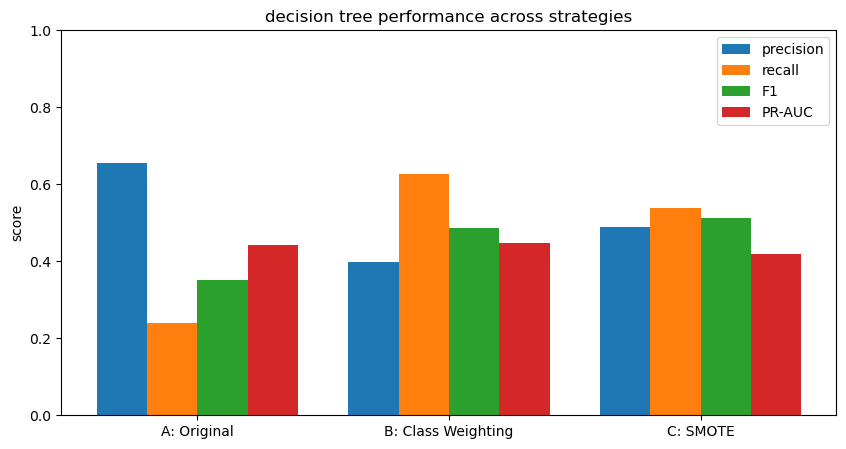

In [32]:
#graphs 
precision_scores = []
recall_scores = []
f1_scores = []
pr_auc_scores = []


#test metrics for each model
for model in models: 

    probabilities = model.predict_proba(X_test)[:,1]
    predictions = (probabilities >= 0.5).astype(int)

    precision_scores.append(precision_score(y_test, predictions))
    recall_scores.append(recall_score(y_test, predictions))
    f1_scores.append(f1_score(y_test, predictions))
    pr_auc_scores.append(average_precision_score(y_test, probabilities))

x = np.arange(3)#set for 3 strats

plt.figure(figsize=(10, 5))

plt.bar(x - 0.3, precision_scores, width=0.2, label="precision")
plt.bar(x - 0.1, recall_scores, width=0.2, label="recall")
plt.bar(x + 0.1, f1_scores, width=0.2, label="F1")
plt.bar(x + 0.3, pr_auc_scores, width=0.2, label="PR-AUC")
#label and display of graph

plt.xticks(x, ["A: Original", "B: Class Weighting", "C: SMOTE"])
plt.ylabel("score")
plt.title("decision tree performance across strategies")
plt.ylim(0,1)
plt.legend()
plt.show()

In [34]:
#exporting results for data analysis

for i in range(3): 
    strategy = strategies[i]

    probabilities = models[i].predict_proba(X_test)[:,1]
    predictions = (probabilities >= 0.5).astype(int) 

    np.savez(f"decision_tree_{strategy}.npz", model="decision tree", strategy=strategy, y_test = y_test, y_test_prob = probabilities, y_test_pred = predictions, train_time_sec=training_times[i], n_train_samples=training_rows[i],best_params=json.dumps(best_params[strategy]),cv_pr_auc_mean=cv_scores[strategy],cv_pr_auc_std=cv_std[strategy])
    
